# Project 2

In [28]:
# import sys
# !{sys.executable} -m pip install jax

In [29]:
# Necessary libraries
import scipy
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.lax as lax
import time
import numpy as np

In [30]:
jax.config.update("jax_enable_x64", True)

### 4.3 Fourth-order symmetric multistep method

In [31]:
# Constants for fourth order symmetric multistep
a1 = -0.7
a2 = 0.1
a3 = 0.9

beta0 = (1/3) * (20*a1*a2*a3 - 4*(a1*a2 + a1*a3 + a2*a3) - 28*(a1 + a2 + a3) - 52)
beta1 = (1/3) * (2*a1*a2*a3 + 14*(a1*a2 + a1*a3 + a2*a3) + 26*(a1 + a2 + a3) + 38)

alpha_list = jnp.array([
    1,           # α₋₄
    -7/5,        # α₋₃
    9/25,        # α₋₂
    22/125,      # α₋₁
    -34/125,     # α₀
    22/125,      # α₁
    9/25,        # α₂
    -7/5,        # α₃
    1            # α₄
])

@jax.jit
def delta_yj(y: jnp.array) -> float:
    """
    Five point central difference centered in y[2]

    y: array on form (y_j-2, y_j-1, y_j, y_j+1, y_j+2). Each y has 3 components

    Returns the central difference
    """

    return 1/12 * (y[:,0] - 8 * y[:,1] + 8* y[:,3] - y[:,4]) 

@jax.jit
def F_j_jax(A_x :jnp.array, x :jnp.array,  h: float, U_grad_xj: jnp.array, A_jacobian: jnp.array) -> jnp.array:
    """
    Fourth order symmetric multistep method help function

    x: array with shape (x_j-2, x_j-1, x_j, x_j+1, x_j+2). Each x has 3 compontents
    h: steplength
    U_grad: potential gradient function

    Returns a 3 component array
    """

    x_j = x[:, 2]
    delta_Aj = delta_yj(A_x)/ h
    vj = delta_yj(x)/ h

    return  A_jacobian.T @ vj - delta_Aj - U_grad_xj


@jax.jit
def fourth_order_sym_multistep_step_fast(x: jnp.array, alpha: jnp.array, h: float, beta0: float, beta1: float, F: tuple) -> jnp.array:

    """
    Takes a step in the fourth order symmetrical multistep method

    x: array on form (x_n-4, x_n-3, ... , x_n+4)
    alpha: array on form (alpha_n-4, alpha_n-3, ... , alpha_n+4)
    h: steplength
    beta0, beta1: method parameters, 
    F: tuple on form (F_n-1, F_n, F_n+1)

    Returns an array x with updated x_n+4
    """

    prev_steps = jnp.sum(x * alpha[:-1], axis = 1)
    x_n4 = 1/ alpha[-1] *( h**2 * (beta1 * F[0] + beta0 * F[1] + beta1 * F[2]) - prev_steps)
    #x[-1] = x_n4

    return x_n4



def fourth_order_sym_multistep_lax(x: jnp.array, v: jnp.array, t_size: int, alpha: jnp.array, h: float, beta0: float, beta1: float, U_grad: callable, A: callable, jacobian: callable) -> jnp.array:

    """
    Fourth order symmetrical multistep method

    x: array with same shape as the final position array, except with the inital 8 values computed
    v: same as x but for velocity
    t_size: number of time points
    alpha: array on form (alpha_n-4, alpha_n-3, ... , alpha_n+4)
    h: steplength
    beta0, beta1: method parameters, 
    U_grad: potential gradient function
    A: magnetic field vector potential function
    Jacobian: Analytically computed jacobian of A 

    Returns a dict with x and v as keys
    """

    def scan_step(carry: tuple, _) -> jnp.array:

        """
        This function does the iterations in the multistep method. We initially implemented the 
        multistep method with numpy and a for loop here, but this took to much time. This function combined with lax.scan
        computes the values at every iteration simultanously

        carry: tuple of values which are updated for each iteration.
               Has the form (x_window, F_prev, F_n, F_next) 
               x_window: array of x_n-4 to x_n+3 (x_n+4 is the value we compute in each iteration)
               F_prev, F_n, F_next: F centered at x_n-1, x_n, x_n+1 respectively


        Returns new carry which are the updated iterative values, and x_last which is 
        an array of every x computed up to this point
        """

        x_window, v_current, F_prev, F_n, F_next = carry 

        # Compute new position
        x_last = fourth_order_sym_multistep_step_fast(x_window, alpha, h, beta0, beta1, (F_prev, F_n, F_next))

        # New window of x_n-4 to x_n+3 (x_n+4 is the value we compute in each iteration)
        new_x_window = jnp.concatenate([x_window[:, 1:], x_last[:, None]],axis=1)

        # Compute velocity as five point difference
        v_current =  delta_yj(new_x_window[:, -5:]) / h 

        # Update the F functions in each itearation
        F_prev = F_n                                        # Need five x-values centered around -5
        F_n = F_next                                        # Need five x-values centered around -4
        A_jacobi_next = jacobian(new_x_window[:, -3])
        U_grad_next = U_grad(new_x_window[:, -3])
        A_next = A(new_x_window[:, -5:])
        F_next = F_j_jax(A_next, new_x_window[:, -5:], h, U_grad_next, A_jacobi_next)     # Need five x-values centered around -3

        # Save current values for next iteration
        new_carry = (new_x_window, v_current, F_prev, F_n, F_next)
        
        return new_carry, (x_last, v_current)

    # Find initial values of the Fs
    A_jacobi_next = jacobian(x[:, 3])
    U_grad_next = U_grad(x[:, 3])
    A_next = A(x[:,  (1): (6)])
    F_prev = F_j_jax(A_next, x[:, (1): (6)],  h, U_grad_next, A_jacobi_next)     # Need five x-values centered around 3

    A_jacobi_next = jacobian(x[:, 4])
    U_grad_next = U_grad(x[:, 4])
    A_next = A(x[:,  (2): (7)])
    F_n = F_j_jax(A_next, x[:, (2): (7)], h, U_grad_next, A_jacobi_next)         # Need five x-values centered around 4

    A_jacobi_next = jacobian(x[:, 5])
    U_grad_next = U_grad(x[:, 5])
    A_next = A(x[:, (3): (8)])
    F_next = F_j_jax(A_next, x[:, (3): (8)], h, U_grad_next, A_jacobi_next)      # Need five x-values centered around 5

    
    # Inital values for lax.scan
    init_x_window = x[:, :8]
    initial_carry = (init_x_window, v[:, 7], F_prev, F_n, F_next)

    # lax.scan computes every value in the multistep iteration simultanously
    final_carry, final_xv = lax.scan(scan_step, initial_carry,  xs= None, length = t_size - 9)

    # Final x holds every x-value computed in the lax scan
    # x holds the 8 initial values
    x_full = jnp.concatenate([x[:, :8], final_xv[0].T],axis=1)
    v_full = jnp.concatenate([v[:, :8], final_xv[1].T],axis=1)

    return {"x": x_full, "v": v_full}

def create_grids(x_0: jnp.array, v_0: jnp.array,  h: float,  t_0: float, t_f: float, B: callable, U_grad: callable):
      
    # Create grids
    t = jnp.arange(t_0, t_f, h)
    x = jnp.zeros(( 3, t.size))
    v = jnp.zeros(( 3, t.size))
    
    # Find first eight x values with solve_ivp RK45
    y_0 = jnp.concatenate((x_0, v_0), axis = None)
    init_sol = scipy.integrate.solve_ivp(charged_particle_eq, (t_0, t[7]), y_0, args = (B, U_grad), dense_output=True, method = "RK45", rtol=1e-10, atol=1e-12)
    x = x.at[:,:8].set(jnp.asarray(init_sol.sol(t[0:8])[:3]))
    v = v.at[:,:8].set( jnp.asarray(init_sol.sol(t[0:8])[3:]))

    return x, v, t


### 5A

In [32]:
# Parameters and constants
T = 1E5
t_0 = 0
h = 0.1 


# Constants for fourth order symmetric multistep
a1 = -0.7
a2 = 0.1
a3 = 0.9

beta0 = (1/3) * (20*a1*a2*a3 - 4*(a1*a2 + a1*a3 + a2*a3) - 28*(a1 + a2 + a3) - 52)
beta1 = (1/3) * (2*a1*a2*a3 + 14*(a1*a2 + a1*a3 + a2*a3) + 26*(a1 + a2 + a3) + 38)

alpha_list = jnp.array([
    1,           # α₋₄
    -7/5,        # α₋₃
    9/25,        # α₋₂
    22/125,      # α₋₁
    -34/125,     # α₀
    22/125,      # α₁
    9/25,        # α₂
    -7/5,        # α₃
    1            # α₄
])


#### 2D charged particle 

In [33]:
# 2D charged particle 
x_0 = jnp.array([0, 1.0, 0.1])
v_0 = jnp.array([0.09, 0.05, 0.20])

def charged_particle_eq(t: float, y: np.array, B: callable, U_grad: callable) -> np.array: 

    """
    RHS of the governing equation of a particle moving in in a static magnetic field

    y: array on form (x1, x2, x2, v1, v2, v3)
    t: time 
    B: function describing magnetic field strength
    U_grad: function describing gradient of electrostatic potential

    Returns the derivative of y according to the equation
    """
    
    
    y_dot = np.cross(y[3:], B(y[:3])) - U_grad(y[:3])
    
    return np.concatenate([y[3:], y_dot])


@jax.jit
def A_charged_jacobian(x: jnp.array) -> jnp.array:

    r = jnp.sqrt(x[0]**2 + x[1]**2)

    return jnp.array([[-1/3*x[0]*x[1]/ r, -1/3 * (r + x[1]**2/ r), 0*r],
                        [1/3 * (r + x[0]**2/r), 1/3 * x[0] * x[1]/r, 0*r],
                        [0*r,                   0*r,                      0*r]])


def B_charged_particle(x: jnp.array) -> jnp.array:

    """
    Static magnetic field for 2D charged particles

    x: position on form (x1, x2, x3)

    Returns the magnetic field strength
    """

    return jnp.array([0, 0, jnp.sqrt(x[0] ** 2 + x[1] ** 2)])

@jax.jit
def A_charged_particle(x: jnp.array) -> np.array:

    """
    Vector potential for static magnetic field for 2D charged particle

    x: position on form (x1, x2, x3)
    
    Returns the vector potential
    """

    dist = jnp.sqrt(x[0] ** 2 + x[1] ** 2)

    return (1/3) * jnp.array([-x[1] * dist, x[0] * dist, 0 * dist])

@jax.jit
def U_charged_particle(x: jnp.array) -> float:
    """
    Electrostatic potential for 2D charged particle
    
    x: position on form (x1, x2, x3)
        
    Returns the potential
    """

    dist = jnp.sqrt(x[0] ** 2 + x[1] ** 2)

    return 1/ (100 * dist)

@jax.jit
def U_grad_charged_particle(x :jnp.array) -> jnp.array:
    """
    Gradient of electrostatic potential for 2D charged particle
        
    x: position on form (x1, x2, x3)
            
    Returns the gradient
    """

    dist = jnp.sqrt(x[0] ** 2 + x[1] ** 2) ** 3

    return -1/100 * jnp.array([x[0] / dist, x[1]/ dist, 0 * dist])


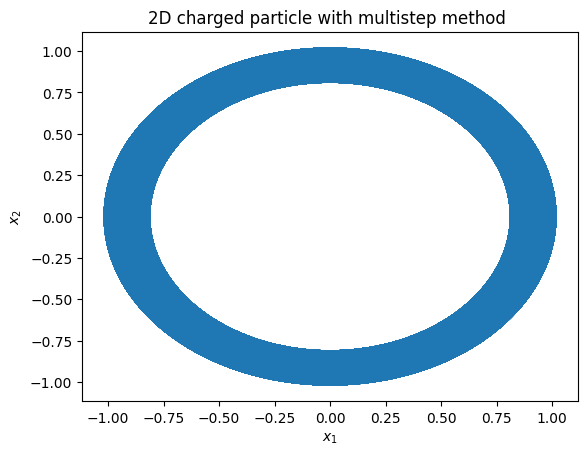

In [34]:
x, v, t = create_grids(x_0, v_0, h, t_0, T, B_charged_particle, U_grad_charged_particle)

results = fourth_order_sym_multistep_lax(x, v, int(t.size), alpha_list, h, beta0, beta1, U_grad_charged_particle, A_charged_particle, A_charged_jacobian)

plt.plot(results["x"][0], results["x"][1])
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("2D charged particle with multistep method ")
plt.show()

Particle has toroidal orbit in 2D plane
- expected since field is radial and potential inverse radial
- shifted a bit each full orbit, which results in plot looking like circle

In [ ]:
# Scipy uses numpy so we redefined the functions below to avoid uneccesary conversions
def B_charged_particle_numpy(x: np.array) -> np.array:

    """
    Static magnetic field for 2D charged particles

    x: position on form (x1, x2, x3)

    Returns the magnetic field strength
    """

    return np.array([0, 0, np.sqrt(x[0] ** 2 + x[1] ** 2)])

def U_grad_charged_particle_numpy(x :np.array) -> np.array:
    """
    Gradient of electrostatic potential for 2D charged particle
        
    x: position on form (x1, x2, x3)
            
    Returns the gradient
    """

    dist = np.sqrt(x[0] ** 2 + x[1] ** 2) ** 3

    return -1/100 * np.array([x[0] / dist, x[1]/ dist, 0 * dist])


# Creating a reference solution to estimate error
y_0 = jnp.concatenate((x_0, v_0), axis = None)
y_0 = np.asarray(y_0)   # Again, scipy uses numpy

# Lowered the tolerances from what was speciefied in the task, as this took a long time
ref_sol = scipy.integrate.solve_ivp(charged_particle_eq, (t_0, T), y_0, args = (B_charged_particle_numpy, U_grad_charged_particle_numpy), t_eval=np.asarray(t), method = "RK45", rtol=1e-8, atol=1e-10)

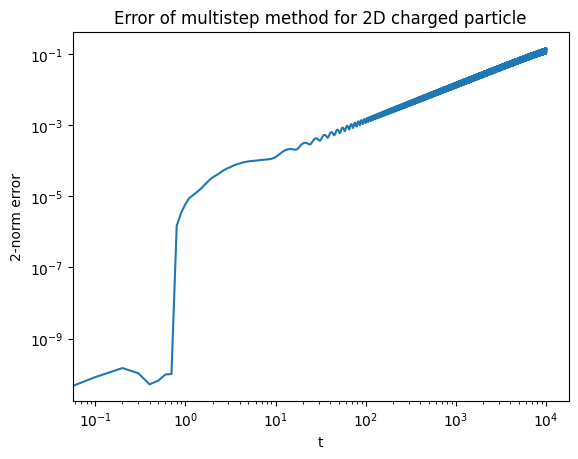

In [ ]:

x_ref = ref_sol.y[:3]
v_ref = ref_sol.y[3:]

multistep_error = np.linalg.norm(np.asarray(results["x"]) - x_ref[:,:-1], ord = 2, axis = 0)

plt.plot(t[:-1], multistep_error)
plt.semilogy()
plt.xscale("log")
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Error of multistep method for 2D charged particle")
plt.show()

Error high for high t, O(h^4) method

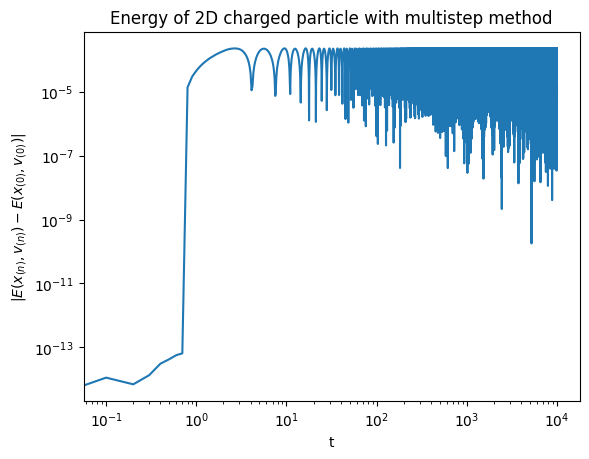

In [ ]:
# Plot change in energy

def E(x: np.array, v: np.array) -> float:

    """
    Energy as sum of kinetic energy and potential energy

    x: position on form (x1, x2, x3)
    v: velocity on form (v1, v2, v3)

    Returns energy as scalar
    """

    return 1/2 * np.linalg.norm(v, ord = 2, axis = 0) ** 2 + np.apply_along_axis(U_charged_particle, 0, x)

# Must exclude last two indices since v is computed by five point difference
energy_diff_multistep = abs(E(results["x"], results["v"]) - E(x_0, v_0))

plt.plot(t[:-1], energy_diff_multistep)
plt.semilogy()
plt.semilogx()
plt.xlabel("t")
plt.ylabel(r"$|E(x_{(n)}, v_{(n)}) - E(x_{(0)}, v_{(0)})|$")
plt.title("Energy of 2D charged particle with multistep method")
plt.show()

Comment on results
- Energy looks constant?


#### Tokamak magnetic field

In [ ]:
# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816e-4,  -2.059e-3])

def B(x: np.array) -> np.array:
    """
    Tokamak magnetic field strength

    x: position on form (x1, x2, x3)
    
    Returns field as vector
    """    
    r = np.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2
    
    return np.array([-(2 * x[1] + x[0]*x[2]) / (2 *r2),
                          (2*x[0] - x[1]*x[2]) / (2* r2),
                                    (r -1) / (2* r)])


def gradU(x: jnp.array) -> jnp.array:
    """
    Gradient of Tokamak magnetic field with jnp arrays
    
    x: position on form (x1, x2, x3)
    
    Returns gradient as vector
    """   
    return 0*x

def A_jax(x: jnp.array) -> jnp.array:
    """
    Vector potential of Tokamak magnetic field with jnp arrays
    
    x: position on form (x1, x2, x3)
    
    Returns vector field as vector
    """
    r = jnp.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2

    # Very i mportant that we use atan2 and not atan
    # atan is 0 if it approaches 0 from above, but pi if it approaches 0 from below
    return jnp.array([0 * r, 
                     1/2  * ( x[0]- jnp.log(r + x[0]) ), 
                     -1/2 * (x[2] * jnp.atan2(x[1], x[0]) + jnp.log(r2)) ])  



@jax.jit
def jacobian_tokamak(x: jnp.array) -> jnp.array:

    """
    Analytically computed Jacobian for A(x) in the Tokamak magnetic field

    x: position on form (x1, x2, x3)

    Returns a 3x3 Jacobian matrix
    """

    r = jnp.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2

    return jnp.array([ [0*r,     0*r     , 0*r],
                      [1/2 - (x[0]/r + 1) / (2 * (x[0] + r)), -x[1] / (2*(x[0] + r) * r), 0*r],
                       [-x[0]/r2 + x[1]*x[2]/(2 * r2), -x[1]/ r2 - x[2] / (2 * x[0] * (1 + (x[1]/ x[0])**2)), -jnp.atan2(x[1], x[0]) / 2]])


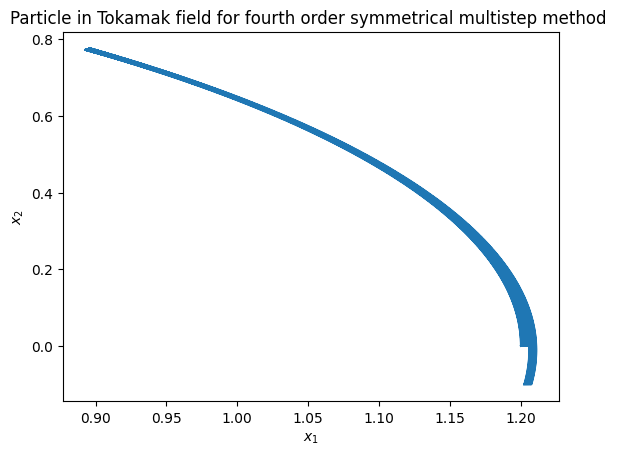

In [ ]:


x, v, t = create_grids(x0, v0, h, t_0, T, B, gradU)


results = fourth_order_sym_multistep_lax(x, v, int(t.size), alpha_list, h, beta0, beta1,  gradU, A_jax, jacobian_tokamak)

# Plotting x2 as function of x1
plt.plot(results["x"][0], results["x"][1])
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Particle in Tokamak field for fourth order symmetrical multistep method ")
plt.show()

We get some extreme values which messes up the plot. Plotting againg for $T=10^3$

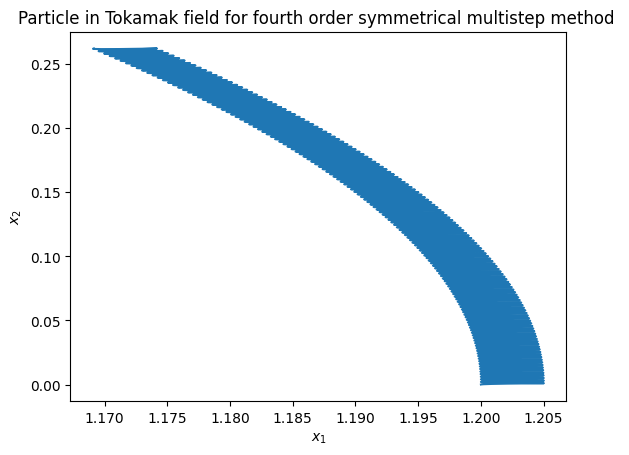

In [ ]:
T_short = 1E3
x_short, v_short, t_short = create_grids(x0, v0, h, t_0, T_short, B, gradU)


results_short = fourth_order_sym_multistep_lax(x_short, v_short, int(t_short.size), alpha_list, h, beta0, beta1,  gradU, A_jax, jacobian_tokamak)

# Plotting x2 as function of x1
plt.plot(results_short["x"][0], results_short["x"][1])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Particle in Tokamak field for fourth order symmetrical multistep method ")
plt.show()

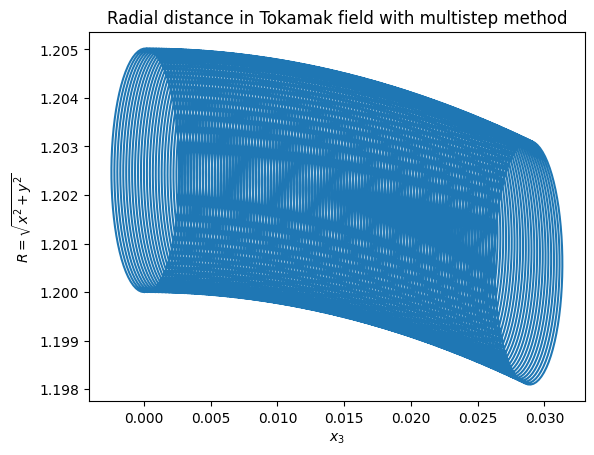

In [ ]:
# Plotting R as function of x3
R = jnp.sqrt((results_short["x"][0]**2 + results_short["x"][1]**2))
plt.plot(results_short["x"][2], R)
plt.xlabel(r"$x_3$")
plt.ylabel(r"$R= \sqrt{x^2 + y^2}$")
plt.title("Radial distance in Tokamak field with multistep method")
plt.show()


Particle is confined to a region of space (banana orbit)

In [ ]:
# Creating a reference solution to estimate error
def B_tokamak(x: np.array) -> np.array:
    r = np.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2
    
    return np.array([-(2 * x[1] + x[0]*x[2]) / (2 *r2),
                          (2*x[0] - x[1]*x[2]) / (2* r2),
                                    (r -1) / (2* r)])


def gradU_tokamak(x: np.array) -> np.array:
    return 0*x

# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816e-4,  -2.059e-3])
T = 1E4
h = 0.1

#results = fourth_order_sym_multistep_lax(x0, v0, alpha_list, h, beta0, beta1, t_0, T, B, gradU, A_jax)
x, v, t = create_grids(x0, v0, h, t_0, T, B, gradU)

# Create a reference solution
y_0 = jnp.concatenate((x0, v0), axis = None)
y_0 = np.asarray(y_0)

# Lowered the tolerances from what was specified in the task, as this takes a long time to run
ref_sol = scipy.integrate.solve_ivp(charged_particle_eq, (t_0, T), y_0, args = (B_tokamak, gradU_tokamak), t_eval=np.asarray(t), method = "RK45", rtol=1e-8, atol=1e-10)

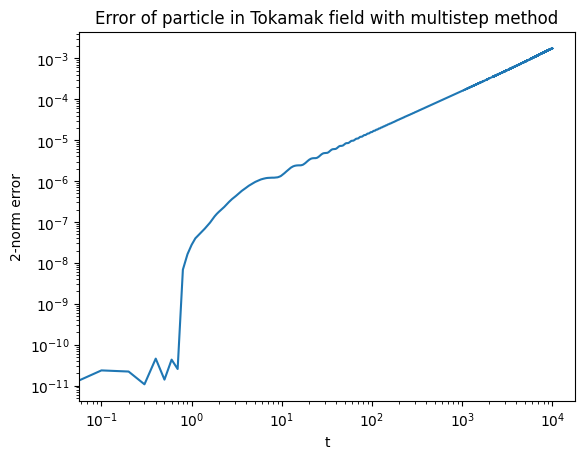

In [ ]:

x_ref = ref_sol.y[:3]
v_ref = ref_sol.y[3:]

multistep_error = np.linalg.norm(np.asarray(results["x"]) - x_ref[:,:-1], ord = 2, axis = 0)

plt.plot(t[:-1], multistep_error)
plt.semilogy()
plt.semilogx()
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Error of particle in Tokamak field with multistep method")
plt.show()

At t= 1000 we have done 10^4 iterations. Since we had O(h^4) error and h=0.1 the error should be O(1) at this points. Don't know why it blows up. Maybe the Jacobi hit the singularity?

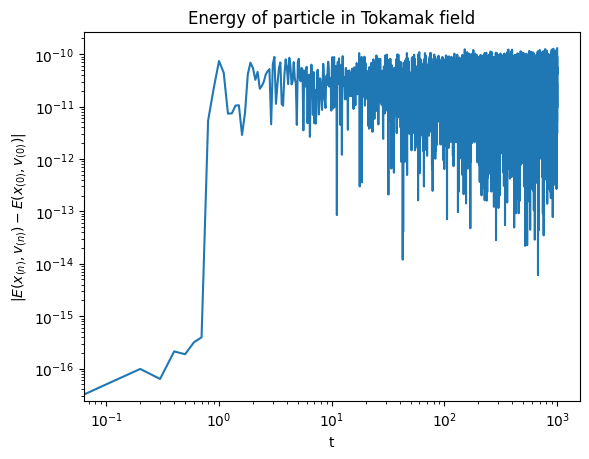

In [ ]:
def U(x):
    return 0

#@jax.jit
def E(x: np.array, v: np.array) -> float:

    """
    Energy as sum of kinetic energy and potential energy

    x: position on form (x1, x2, x3)
    v: velocity on form (v1, v2, v3)

    Returns energy as scalar
    """

    return 1/2 * np.linalg.norm(v, ord = 2, axis = 0) ** 2 + np.apply_along_axis(U, 0, x)

# Must exclude last two indices since v is computed by five point difference
energy_diff_multistep = abs(E(results_short["x"], results_short["v"]) - E(x0, v0))

plt.plot(t_short[:-1], energy_diff_multistep)
plt.semilogy()
plt.semilogx()
plt.xlabel("t")
plt.ylabel(r"$|E(x_{(n)}, v_{(n)}) - E(x_{(0)}, v_{(0)})|$")
plt.title("Energy of particle in Tokamak field")
plt.show()

### 5B

#### 2D charged particle with fourth-order symmetric multistep method

In [ ]:
# Create a reference solution which can be used for different time grids

T = 1E3
# 2D charged particle 
x_0 = jnp.array([0, 1.0, 0.1])
v_0 = jnp.array([0.09, 0.05, 0.20])

# Create a reference solution
y_0 = jnp.concatenate((x_0, v_0), axis = None)
y_0 = np.asarray(y_0)


ref_sol_dense =  scipy.integrate.solve_ivp(charged_particle_eq, (t_0, T), y_0, args = (B_charged_particle_numpy, U_grad_charged_particle_numpy), dense_output= True, method = "RK45", rtol=1e-10, atol=1e-12)

In [ ]:
errors = []
h_list = []
h4_list = []
times = []


N = 7
h = 0.1

for i in range(N):

    h_list.append(h)
    h4_list.append(h**4)
    
    x, v, t = create_grids(x_0, v_0, h, t_0, T, B_charged_particle, U_grad_charged_particle)
    x_ref = ref_sol_dense.sol(t)[:3][:, :-1]
    v_ref = ref_sol_dense.sol(t)[3:][:, :-1]

    start = time.perf_counter()
    results = fourth_order_sym_multistep_lax(x, v, int(t.size), alpha_list, h, beta0, beta1,  U_grad_charged_particle, A_charged_particle, A_charged_jacobian)
    stop = time.perf_counter()

   
    times.append(stop-start)

    errors.append( np.linalg.norm(np.asarray(results["x"]) - x_ref, ord = 2))
    h /= 2


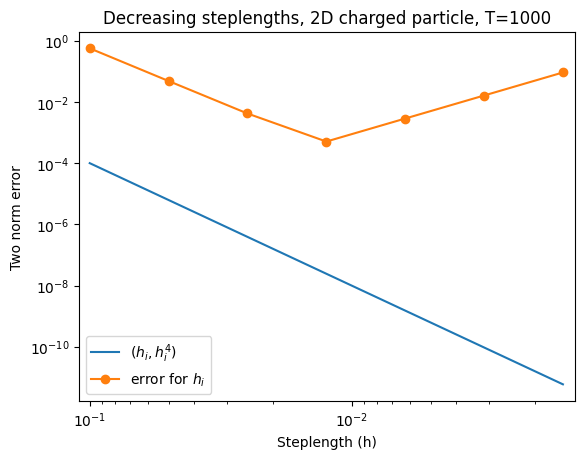

In [ ]:
# Plotting errors over steplengths

# We expect order 4 so the error graph should be paralell to (h_i, h_i^4)
plt.plot(h_list, h4_list, label = r"$(h_i, h_i^4)$")
    
plt.plot(h_list, errors, label = r"error for $h_i$", marker = "o")
plt.loglog()
plt.xlabel("Steplength (h)")
plt.xlim(h_list[0] + 0.1 * h_list[0], h_list[-1] - 0.1 * h_list[-1])
plt.ylabel("Two norm error")
plt.title(f"Decreasing steplengths, 2D charged particle, T={int(T)}")
plt.legend()
plt.show()

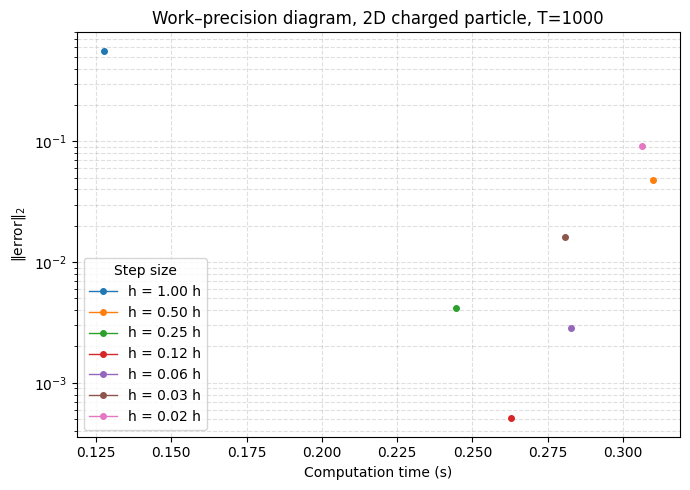

In [ ]:
# Plotting computing times
fig, ax = plt.subplots(figsize=(7, 5))

for i in range(N):
    ax.plot(times[i], errors[i], marker="o", markersize=4,
            linewidth=1, label=f"h = {h_list[i]/0.1:.2f} h")

ax.set_yscale("log")

ax.set_xlabel("Computation time (s)")
ax.set_ylabel(r"$\|\mathrm{error}\|_2$")
ax.set_title(f"Work–precision diagram, 2D charged particle, T={int(T)}")
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(title="Step size", frameon=True)

fig.tight_layout()
plt.show()

#### Tokamak magnetic field with fourth-order symmetric multistep method

In [ ]:
def B(x: np.array) -> np.array:
    r = np.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2
    
    return np.array([-(2 * x[1] + x[0]*x[2]) / (2 *r2),
                          (2*x[0] - x[1]*x[2]) / (2* r2),
                                    (r -1) / (2* r)])


def gradU(x: np.array) -> np.array:
    return 0*x

# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816e-4,  -2.059e-3])


#results = fourth_order_sym_multistep_lax(x0, v0, alpha_list, h, beta0, beta1, t_0, T, B, gradU, A_jax)
x, v, t = create_grids(x0, v0, h, t_0, T, B, gradU)

# Create a reference solution
y_0 = jnp.concatenate((x0, v0), axis = None)
y_0 = np.asarray(y_0)


ref_sol = scipy.integrate.solve_ivp(charged_particle_eq, (t_0, T), y_0, args = (B, gradU), t_eval=np.asarray(t), method = "RK45", rtol=1e-8, atol=1e-10)

In [ ]:
T = 1E3
ref_sol_dense = ref_sol = scipy.integrate.solve_ivp(charged_particle_eq, (t_0, T), y_0, args = (B, gradU), dense_output= True, method = "RK45", rtol=1e-10, atol=1e-12)

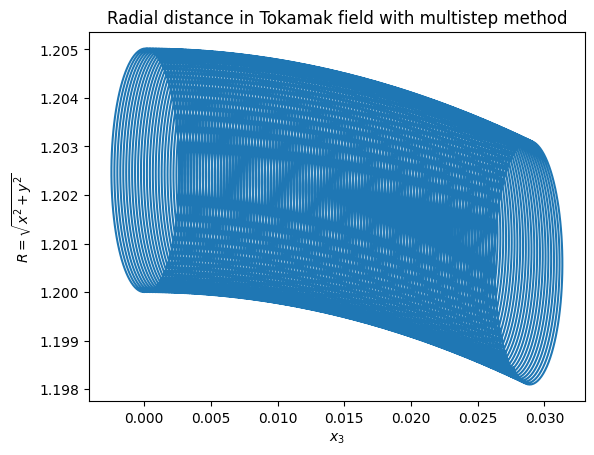

In [ ]:
# (REMOVE THIS)
# JUST CHECKING IF THE TOKAMAK SOLUTION IS CORRECT
x_ref = ref_sol.y[:3]
v_ref = ref_sol.y[3:]

R = jnp.sqrt((x_ref[0]**2 + x_ref[1]**2))
plt.plot(x_ref[2], R)
plt.xlabel(r"$x_3$")
plt.ylabel(r"$R= \sqrt{x^2 + y^2}$")
plt.title("Radial distance in Tokamak field with multistep method")
plt.show()

In [ ]:
errors = []
h_list = []
h4_list = []
times = []

def gradU_jax(x: jnp.array) -> jnp.array:
    return 0*x


N = 7
h = 0.1

for i in range(N):

    h_list.append(h)
    h4_list.append(h**4)
    
    x, v, t = create_grids(x0, v0, h, t_0, T, B, gradU)
    x_ref = ref_sol_dense.sol(t)[:3][:, :-1]
    v_ref = ref_sol_dense.sol(t)[3:][:, :-1]

    start = time.perf_counter()
    results = fourth_order_sym_multistep_lax(x, v, int(t.size), alpha_list, h, beta0, beta1,  gradU_jax, A_jax, jacobian_tokamak)
    stop = time.perf_counter()

   
    times.append(stop-start)

    errors.append( np.linalg.norm(np.asarray(results["x"]) - x_ref, ord = 2))

    h /= 2

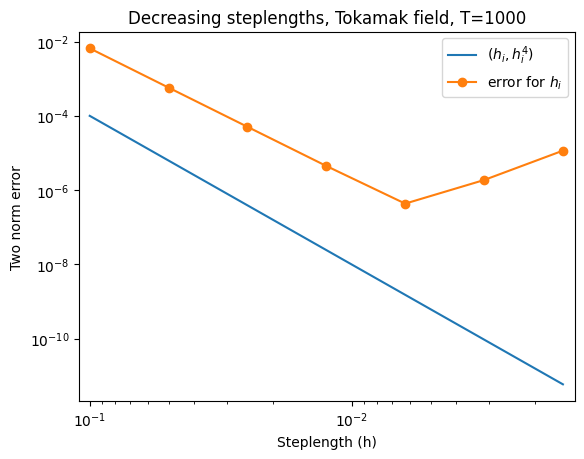

In [ ]:
# Plotting errors over steplengths

# We expect order 4 so the error graph should be paralell to (h_i, h_i^4)
plt.plot(h_list, h4_list, label = r"$(h_i, h_i^4)$")
    
plt.plot(h_list, errors, label = r"error for $h_i$", marker = "o")
plt.loglog()
plt.xlabel("Steplength (h)")
plt.xlim(h_list[0] + 0.1 * h_list[0], h_list[-1] - 0.1 * h_list[-1])
plt.ylabel("Two norm error")
plt.title(f"Decreasing steplengths, Tokamak field, T={int(T)}")
plt.legend()
plt.show()

Looks like we have O(h^4) error like we should.
- higher error for small steplengths because of rounding errors?

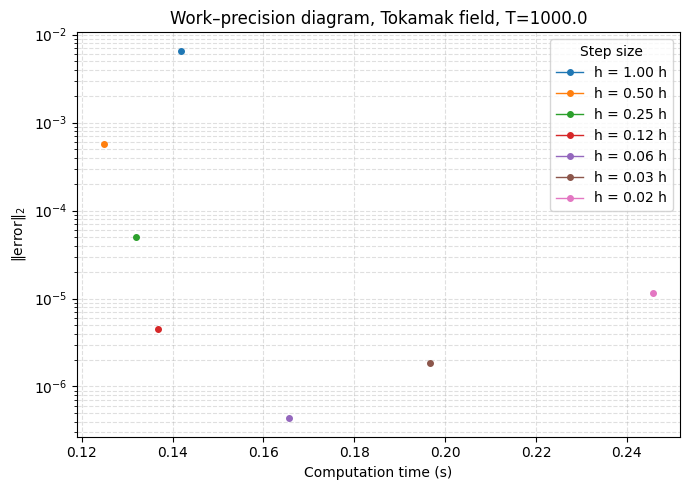

In [ ]:
import matplotlib.ticker as mticker

# Plotting computing times
fig, ax = plt.subplots(figsize=(7, 5))

for i in range(N):
    ax.plot(times[i], errors[i], marker="o", markersize=4,
            linewidth=1, label=f"h = {h_list[i]/0.1:.2f} h")

ax.set_yscale("log")

ax.set_xlabel("Computation time (s)")
ax.set_ylabel(r"$\|\mathrm{error}\|_2$")
ax.set_title(f"Work–precision diagram, Tokamak field, T={T}")
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(title="Step size", frameon=True)

fig.tight_layout()
plt.show()

Using a linear x-axis here, even though the task asks for a log-log plot, because the values was so closed in time

May be counterintuitive that some of the lower hs have higher computing times. This is likely due to JIT and lax.scan which are made to handle large datasets